# Tarea 1 – Ideas de innovación (bonus)

Tres análisis sobre `datos/noticias.csv`. Se apoyan uno en otro:

1. **Buscador semántico.** Cada noticia se convierte en un vector (*embedding*) y se busca por similitud coseno.
   Esos mismos vectores alimentan el buscador del dashboard y el emparejamiento del punto 3.
2. **NER peruano.** Las entidades nombradas (personas, instituciones, lugares) más frecuentes por categoría y por
   medio: ¿a quién nombra cada diario?
3. **Sesgo comparativo (Opción C).** Se busca la misma noticia contada por La República y El Comercio y se compara
   cómo la titula cada uno y si el clasificador cambia su predicción. Se completa con las palabras que distinguen
   a cada diario.

Todo lo pesado se calcula aquí y se guarda en `datos/`, así el dashboard solo lee archivos livianos.

In [1]:
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
from IPython.display import display

import kanagawa  # paleta compartida con el dashboard; registra la plantilla de Plotly "kanagawa"

pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width, pio.renderers["png"].height = 950, 520
pio.templates.default = "plotly_dark+kanagawa"
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 80)

SEED = 42
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
COLORES_MEDIO = kanagawa.COLORES_MEDIO
DATOS, MODELO = Path("datos"), Path("modelo")

df = pd.read_csv(DATOS / "noticias.csv")
df = df.merge(pd.read_csv(DATOS / "split.csv"), on="url", how="left", validate="one_to_one")
df["fecha_dt"] = pd.to_datetime(df["fecha"])
print(df.shape)

(444, 9)


## 1. Embeddings y buscador semántico

* **Modelo:** `intfloat/multilingual-e5-small`, que convierte un texto en un vector de 384 números de forma que
  textos con significado parecido quedan cerca.
* **Prefijos:** e5 se entrenó con `passage: ` para los documentos y `query: ` para las consultas. Sin ellos, la
  calidad de la búsqueda cae.
* **Similitud coseno:** con vectores normalizados (largo 1), el coseno es simplemente el producto punto: `E @ q`.
* **Por qué semántico y no palabras clave:** "sube el dólar" encuentra notas sobre el *tipo de cambio* aunque no
  repitan las mismas palabras.

Se codifica titular + bajada: más contexto da mejores vectores. El dashboard codifica la consulta del usuario
con el mismo modelo.

In [2]:
from sentence_transformers import SentenceTransformer

MODELO_EMB = "intfloat/multilingual-e5-small"
embedder = SentenceTransformer(MODELO_EMB, device="cpu")

textos = ("passage: " + df["titular"] + ". " + df["bajada"]).tolist()
E = embedder.encode(textos, normalize_embeddings=True, batch_size=32, show_progress_bar=False).astype(np.float32)
np.save(DATOS / "embeddings.npy", E)
print("Embeddings:", E.shape, "→ datos/embeddings.npy (mismo orden de filas que noticias.csv)")


def buscar(consulta, k=5):
    q = embedder.encode([f"query: {consulta}"], normalize_embeddings=True)[0]
    sims = E @ q
    top = np.argsort(-sims)[:k]
    return df.iloc[top][["medio", "etiqueta", "titular"]].assign(similitud=sims[top].round(3)).reset_index(drop=True)


for consulta in ["sube el dólar", "clásico del fútbol peruano", "inteligencia artificial y empleo",
                 "enfrentamiento entre el Congreso y el Ejecutivo"]:
    print(f"\nConsulta: «{consulta}»")
    display(buscar(consulta))

C:\Users\DOKU\Documents\GitHub\intermediate-python-hw\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4574.92it/s]

Embeddings: (444, 384) → datos/embeddings.npy (mismo orden de filas que noticias.csv)

Consulta: «sube el dólar»


,medio,etiqueta,titular,similitud
0,El Comercio,economia,"El dólar abre en S/3,44 ante retroceso de la divisa estadounidense a nivel global",0.879
1,El Comercio,economia,"El dólar cierra al alza en S/3,44 ante fortalecimiento global de la divisa",0.877
2,El Comercio,economia,"El dólar abre a la baja en S/3,42 ante debilitamiento de la divisa estadounidense",0.877
3,El Comercio,economia,"El dólar abre al alza en S/3,44, pero retrocede ante mayor oferta local",0.876
4,El Comercio,economia,"El dólar cierra al alza en S/3,43 pese al retroceso de la divisa estadounidense",0.872


...

,medio,etiqueta,titular,similitud
0,El Comercio,deportes,¡Por primera vez en el Clausura! Piero Cari será convocado para el duelo de Alianza Lima ante At...,0.849
1,La Republica,deportes,Selección peruana confirmó nuevo amistoso para la fecha FIFA de noviembre: la 'Bicolor' enfrenta...,0.838
2,La Republica,deportes,¡Triunfazo blanquiazul! Alianza Lima venció 2-1 a Cusco FC y se mantiene en la lucha por el Torn...,0.830
3,La Republica,deportes,¡Perú es clave! La Selección Peruana venció 3-1 a Venezuela y es líder de su grupo en el Sudamer...,0.828
4,La Republica,deportes,Paolo Guerrero involucrado en polémica de diplomas para entrenadores: revelan declaraciones sobr...,0.825



Consulta: «inteligencia artificial y empleo»


,medio,etiqueta,titular,similitud
0,El Comercio,economia,Creación de agentes de IA se multiplicó por 15 en el último año: ¿cómo impacta en la productivid...,0.877
1,El Comercio,ciencia_tecnologia,"Las empresas de IA son incapaces de controlar sus modelos, alerta un exinvestigador de OpenAI",0.856
2,El Comercio,economia,"De consultar saldos a delegar operaciones, ¿cómo cambiará la banca con la IA hacia 2030?",0.853
3,El Comercio,ciencia_tecnologia,Meta presenta nuevo modelo de IA y afirma que está al nivel de OpenAI y Anthropic,0.850
4,El Comercio,ciencia_tecnologia,Intel en Latinoamérica: “Los gobiernos deben crear condiciones o reglas para un uso saludable de...,0.848



Consulta: «enfrentamiento entre el Congreso y el Ejecutivo»


,medio,etiqueta,titular,similitud
0,El Comercio,politica,Tenso altercado en plena sesión del Senado: Así se desarrolló el incidente entre Iber Maraví y e...,0.868
1,El Comercio,politica,Miguel Torres: “Dejemos atrás los enfrentamientos y continuemos con el debate de las facultades ...,0.859
2,La Republica,politica,Senador de JP cuestiona a Astudillo por confrontación en la Comisión de Constitución: “No se pue...,0.854
3,La Republica,politica,Comisión de Constitución del Senado reanuda este martes el debate sobre la delegación de faculta...,0.852
4,El Comercio,politica,Ministro Rafael Belaunde sobre altercado en el Congreso: “Hay gente que está en el Parlamento pa...,0.847


### ¿Los vectores capturan el tema?

Prueba de cordura: para cada noticia se miran sus 5 vecinos más cercanos (sin contarse a sí misma) y se cuenta qué
fracción comparte su categoría. Si los vectores no supieran nada del tema, sería ~25 % (4 categorías balanceadas).

In [3]:
S = E @ E.T
np.fill_diagonal(S, -1)
vecinos = np.argsort(-S, axis=1)[:, :5]
etiquetas = df["etiqueta"].to_numpy()
pureza = (etiquetas[vecinos] == etiquetas[:, None]).mean(axis=1)
print(f"Vecinos con la misma categoría: {pureza.mean():.1%} (azar ≈ 25 %)")
display(pd.Series(pureza).groupby(df["etiqueta"]).mean().rename("pureza de vecinos").round(3).to_frame())

Vecinos con la misma categoría: 89.7% (azar ≈ 25 %)


,pureza de vecinos
etiqueta,
ciencia_tecnologia,0.881
deportes,0.957
economia,0.867
politica,0.881


## 2. NER: entidades más frecuentes por categoría y por medio

Se usa `mrm8488/bert-spanish-cased-finetuned-ner` (BETO ajustado para NER en español) sobre titular + bajada.

* `aggregation_strategy="simple"` une los sub-tokens (`Fuji`, `##mori`) en una sola entidad.
* Se conservan las entidades con confianza ≥ 0.80 y se cuenta **una vez por noticia**: interesa en cuántas noticias
  aparece alguien, no cuántas veces se lo repite.
* Tipos: `PER` (persona), `ORG` (organización), `LOC` (lugar), `MISC` (otros).

In [4]:
from transformers import pipeline

ner = pipeline("ner", model="mrm8488/bert-spanish-cased-finetuned-ner", aggregation_strategy="simple", device="cpu")
salidas = ner((df["titular"] + ". " + df["bajada"]).tolist(), batch_size=16)

filas = []
for noticia, entidades in zip(df.itertuples(), salidas):
    for e in entidades:
        nombre = re.sub(r"\s+", " ", e["word"].replace("##", "")).strip(" .,:;\"'“”«»")
        if e["score"] >= 0.80 and len(nombre) > 2:
            filas.append({"url": noticia.url, "medio": noticia.medio, "etiqueta": noticia.etiqueta,
                          "entidad": nombre, "tipo": e["entity_group"], "score": round(float(e["score"]), 3)})
entidades = pd.DataFrame(filas).drop_duplicates(["url", "entidad"])
entidades.to_csv(DATOS / "ner_entidades.csv", index=False, encoding="utf-8")
print(f"{len(entidades)} menciones de {entidades['entidad'].nunique()} entidades distintas → datos/ner_entidades.csv")
display(entidades["tipo"].value_counts().to_frame("menciones"))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 12012.18it/s]


[transformers] BertForTokenClassification LOAD REPORT from: mrm8488/bert-spanish-cased-finetuned-ner
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


1515 menciones de 876 entidades distintas → datos/ner_entidades.csv


,menciones
tipo,
ORG,624
MISC,350
PER,335
LOC,206


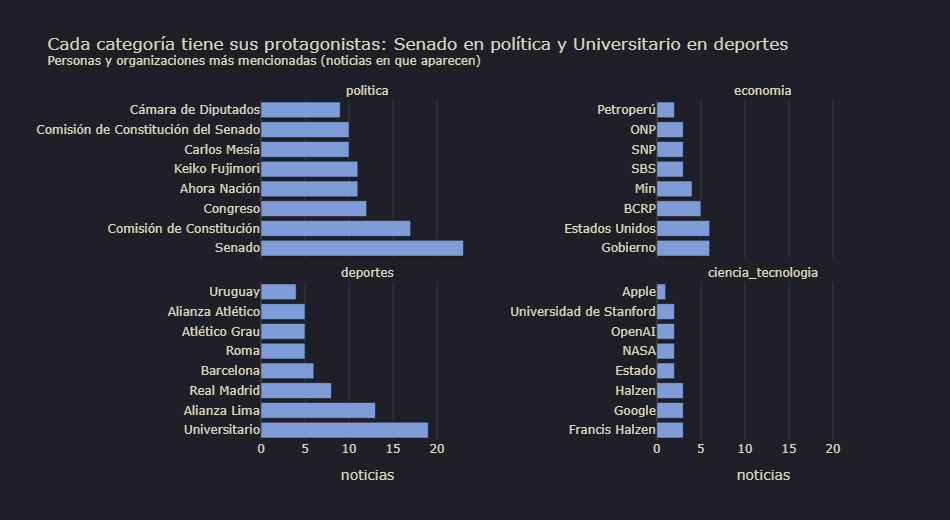

In [5]:
top_cat = (entidades[entidades["tipo"].isin(["PER", "ORG"])]
           .groupby(["etiqueta", "entidad"]).size().rename("noticias").reset_index()
           .sort_values("noticias", ascending=False).groupby("etiqueta").head(8))
lider = top_cat.groupby("etiqueta").first()
fig = px.bar(top_cat, x="noticias", y="entidad", facet_col="etiqueta", facet_col_wrap=2, orientation="h",
             category_orders={"etiqueta": CATEGORIAS}, height=700, facet_col_spacing=0.3,
             title=(f"Cada categoría tiene sus protagonistas: {lider.loc['politica', 'entidad']} en política y "
                    f"{lider.loc['deportes', 'entidad']} en deportes"
                    f"<br><sup>Personas y organizaciones más mencionadas (noticias en que aparecen)</sup>"))
fig.update_yaxes(matches=None, showticklabels=True, title="")
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

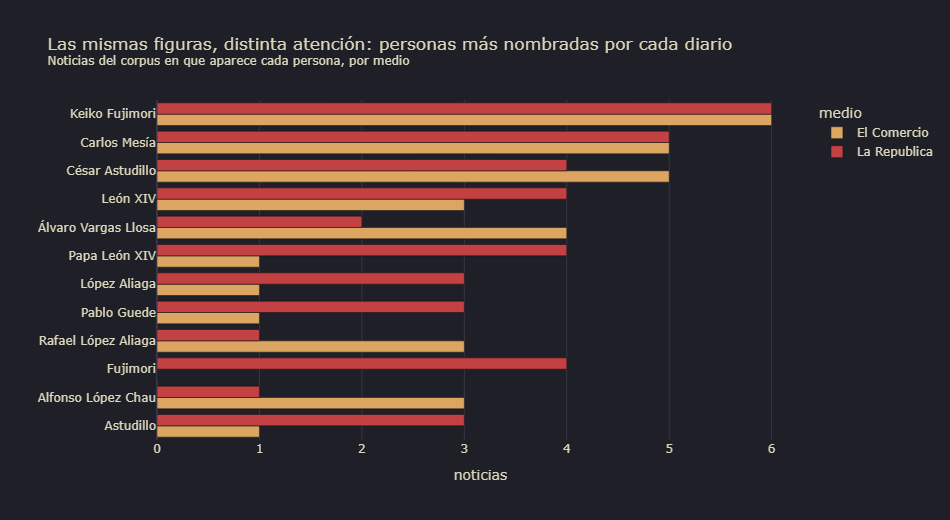

medio,El Comercio,La Republica
entidad,,
Keiko Fujimori,6,6
Carlos Mesía,5,5
César Astudillo,5,4
León XIV,3,4
Álvaro Vargas Llosa,4,2
Papa León XIV,1,4
Astudillo,1,3
Alfonso López Chau,3,1
Fujimori,0,4


In [6]:
personas = entidades[entidades["tipo"] == "PER"]
conteo = personas.groupby(["entidad", "medio"]).size().unstack(fill_value=0)
conteo = conteo.loc[conteo.sum(axis=1).sort_values(ascending=False).index[:12]]
top_medio = conteo.reset_index().melt(id_vars="entidad", var_name="medio", value_name="noticias")
fig = px.bar(top_medio, x="noticias", y="entidad", color="medio", barmode="group", orientation="h",
             color_discrete_map=COLORES_MEDIO, height=560,
             title=("Las mismas figuras, distinta atención: personas más nombradas por cada diario"
                    "<br><sup>Noticias del corpus en que aparece cada persona, por medio</sup>"))
fig.update_yaxes(categoryorder="total ascending", title="")
fig.show()
display(conteo)

## 3. Sesgo comparativo: la misma noticia en dos diarios

**Emparejamiento automático.** Para cada noticia de La República se busca la noticia de El Comercio más parecida
(coseno de embeddings) publicada con ±2 días de diferencia. Un par se acepta como candidato solo si es
**mejor mutuo**: la nota de El Comercio también tiene a esa nota de La República como la más parecida.

**Confirmación humana.** La similitud alta no garantiza que sea el mismo hecho (dos partidos distintos del mismo
torneo se parecen mucho). Por eso cada candidato se revisa a mano en `datos/pares_revision.csv`, marcando la
columna `misma_noticia` con `si` o `no`.

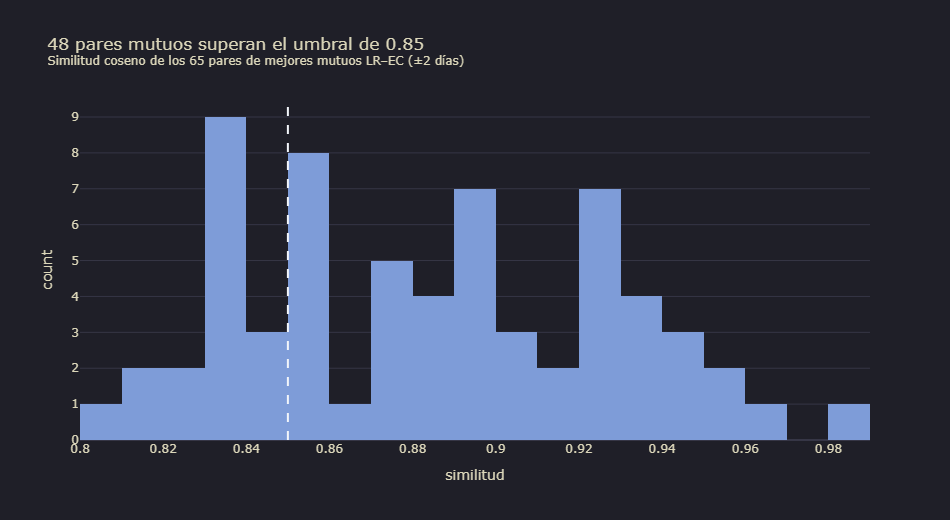

Candidatos a revisar: 30


In [7]:
UMBRAL = 0.85
MAX_CANDIDATOS = 30

lr = df[df["medio"] == "La Republica"].reset_index()
ec = df[df["medio"] == "El Comercio"].reset_index()
sim = E[lr["index"]] @ E[ec["index"]].T
dias = np.abs((lr["fecha_dt"].to_numpy()[:, None] - ec["fecha_dt"].to_numpy()[None, :]) / np.timedelta64(1, "D"))
sim = np.where(dias <= 2, sim, -1.0)

mejor_ec, mejor_lr = sim.argmax(axis=1), sim.argmax(axis=0)
mutuos = pd.DataFrame([{"i_lr": i, "i_ec": j, "similitud": sim[i, j]}
                       for i, j in enumerate(mejor_ec) if mejor_lr[j] == i and sim[i, j] > 0])
fig = px.histogram(mutuos, x="similitud", nbins=30,
                   title=(f"{(mutuos['similitud'] >= UMBRAL).sum()} pares mutuos superan el umbral de {UMBRAL}"
                          f"<br><sup>Similitud coseno de los {len(mutuos)} pares de mejores mutuos LR–EC (±2 días)</sup>"))
fig.add_vline(x=UMBRAL, line_dash="dash")
fig.show()

candidatos = mutuos[mutuos["similitud"] >= UMBRAL].nlargest(MAX_CANDIDATOS, "similitud").reset_index(drop=True)
candidatos["id"] = candidatos.index + 1
candidatos["url_lr"] = lr.loc[candidatos["i_lr"], "url"].to_numpy()
candidatos["url_ec"] = ec.loc[candidatos["i_ec"], "url"].to_numpy()
candidatos["titular_lr"] = lr.loc[candidatos["i_lr"], "titular"].to_numpy()
candidatos["titular_ec"] = ec.loc[candidatos["i_ec"], "titular"].to_numpy()
print(f"Candidatos a revisar: {len(candidatos)}")

In [8]:
RUTA_REVISION = DATOS / "pares_revision.csv"
if not RUTA_REVISION.exists():
    (candidatos[["id", "similitud", "titular_lr", "titular_ec", "url_lr", "url_ec"]].round({"similitud": 3})
     .assign(misma_noticia="").to_csv(RUTA_REVISION, index=False, encoding="utf-8-sig"))
    raise SystemExit("Plantilla creada en datos/pares_revision.csv: marcar misma_noticia (si/no) y volver a ejecutar.")

revision = pd.read_csv(RUTA_REVISION, encoding="utf-8-sig")
revision["misma_noticia"] = revision["misma_noticia"].astype(str).str.strip().str.lower()
assert revision["misma_noticia"].isin(["si", "no"]).all(), "Falta marcar misma_noticia (si/no) en algún par"
pares = revision[revision["misma_noticia"] == "si"].copy()
print(f"Pares confirmados como la misma noticia: {len(pares)} de {len(revision)} candidatos")

Pares confirmados como la misma noticia: 19 de 30 candidatos


### ¿Cambia la predicción según quién titula?

Para cada par confirmado se compara:

* **Sección editorial:** ¿ambos diarios publicaron la noticia en la misma sección?
* **Predicción del clasificador** (el DistilBERT de la Parte 2): ¿predice la misma categoría con los dos titulares,
  y con cuánta confianza?
* **Estilo:** largo del titular, uso de comillas (citas textuales) y de preguntas.

> **Limitación:** si un titular de un par estuvo en el set de entrenamiento, el modelo ya lo vio y su predicción es
> optimista. Por eso se reporta en qué partición cayó cada titular.

In [9]:
from transformers import pipeline

clasificador = pipeline("text-classification", model=str(MODELO), top_k=None, device="cpu")


def predecir(titular):
    salida = clasificador(titular)
    salida = salida[0] if isinstance(salida[0], list) else salida
    mejor = max(salida, key=lambda s: s["score"])
    return mejor["label"], round(mejor["score"], 3)


info = df.set_index("url")
for medio in ["lr", "ec"]:
    pares[[f"pred_{medio}", f"prob_{medio}"]] = [predecir(t) for t in pares[f"titular_{medio}"]]
    pares[f"seccion_{medio}"] = pares[f"url_{medio}"].map(info["etiqueta"])
    pares[f"particion_{medio}"] = pares[f"url_{medio}"].map(info["particion"])
    pares[f"largo_{medio}"] = pares[f"titular_{medio}"].str.len()
    pares[f"comillas_{medio}"] = pares[f"titular_{medio}"].str.contains(r"[\"“”«»]")
    pares[f"pregunta_{medio}"] = pares[f"titular_{medio}"].str.contains(r"[¿?]")

resumen = pd.Series({
    "pares confirmados": len(pares),
    "misma sección editorial": f"{(pares['seccion_lr'] == pares['seccion_ec']).mean():.0%}",
    "misma predicción del modelo": f"{(pares['pred_lr'] == pares['pred_ec']).mean():.0%}",
    "diferencia media de confianza": f"{(pares['prob_lr'] - pares['prob_ec']).abs().mean():.3f}",
    "largo medio LR vs EC": f"{pares['largo_lr'].mean():.0f} vs {pares['largo_ec'].mean():.0f} caracteres",
    "titulares con comillas LR vs EC": f"{pares['comillas_lr'].mean():.0%} vs {pares['comillas_ec'].mean():.0%}",
    "titulares con pregunta LR vs EC": f"{pares['pregunta_lr'].mean():.0%} vs {pares['pregunta_ec'].mean():.0%}",
    "pares con ambos titulares fuera de train": int(((pares["particion_lr"] != "train")
                                                     & (pares["particion_ec"] != "train")).sum()),
}).to_frame("valor")
display(resumen)

columnas = ["similitud", "titular_lr", "titular_ec", "seccion_lr", "seccion_ec", "pred_lr", "prob_lr",
            "pred_ec", "prob_ec"]
print("Pares donde cambia la sección o la predicción:")
display(pares.loc[(pares["pred_lr"] != pares["pred_ec"]) | (pares["seccion_lr"] != pares["seccion_ec"]), columnas])
pares.drop(columns=["misma_noticia"]).to_csv(DATOS / "pares_sesgo.csv", index=False, encoding="utf-8")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 4138.04it/s]

,valor
pares confirmados,19
misma sección editorial,95%
misma predicción del modelo,95%
diferencia media de confianza,0.023
largo medio LR vs EC,108 vs 107 caracteres
titulares con comillas LR vs EC,37% vs 42%
titulares con pregunta LR vs EC,0% vs 16%
pares con ambos titulares fuera de train,2


Pares donde cambia la sección o la predicción:


,similitud,titular_lr,titular_ec,seccion_lr,seccion_ec,pred_lr,prob_lr,pred_ec,prob_ec
9,0.935,Vaticano informa que Papa León XIV tiene cáncer pulmonar,León XIV fue operado de cáncer de pulmón: qué implica la extirpación de un lóbulo y cómo es la r...,politica,ciencia_tecnologia,politica,0.707,ciencia_tecnologia,0.893


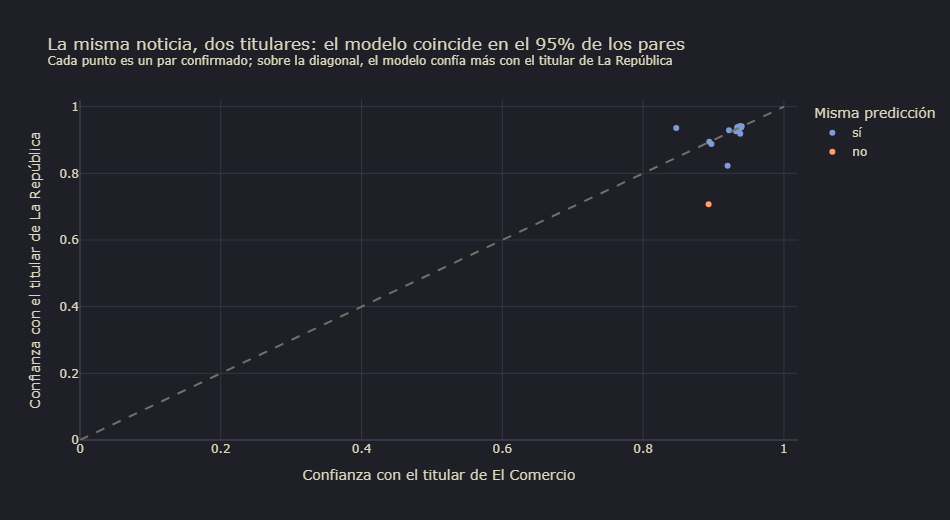

In [10]:
misma = np.where(pares["pred_lr"] == pares["pred_ec"], "sí", "no")
fig = px.scatter(pares, x="prob_ec", y="prob_lr", color=misma,
                 hover_data=["titular_lr", "titular_ec"], range_x=[0, 1.02], range_y=[0, 1.02],
                 color_discrete_map={"sí": kanagawa.SERIE, "no": kanagawa.CONTRASTE},
                 labels={"prob_ec": "Confianza con el titular de El Comercio",
                         "prob_lr": "Confianza con el titular de La República", "color": "Misma predicción"},
                 title=(f"La misma noticia, dos titulares: el modelo coincide en el "
                        f"{(pares['pred_lr'] == pares['pred_ec']).mean():.0%} de los pares"
                        f"<br><sup>Cada punto es un par confirmado; sobre la diagonal, el modelo confía más con el "
                        f"titular de La República</sup>"))
fig.add_shape(type="line", x0=0, y0=0, x1=1, y1=1, line=dict(dash="dash", color=kanagawa.GRIS))
fig.show()

### ¿Qué palabras distinguen a cada diario?

Sobre todo el corpus (no solo los pares) se calcula el **log-odds ratio** de cada palabra entre ambos diarios:
cuánto más probable es encontrarla en un titular de un medio que en el del otro. Se suaviza con +1 para que las
palabras raras no dominen y se exige que aparezcan al menos 5 veces.

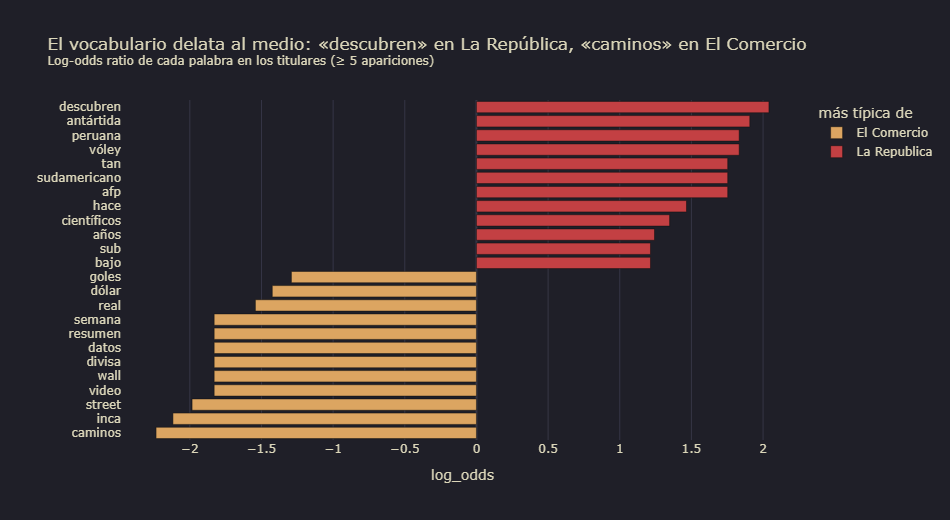

In [11]:
STOPWORDS = set("""de la el en y a los las del que se por un una con para su al es lo como más o sus le ya
este esta qué cómo cuándo dónde sobre tras sin ser fue son han hay ha entre desde hasta e u ni no si sí
pero muy también así todo todos otra otro otras otros mismo según ante contra durante hoy""".split())


def palabras(texto):
    return [p for p in re.findall(r"[a-záéíóúñü]+", texto.lower()) if p not in STOPWORDS and len(p) > 2]


conteos = {m: Counter(p for t in g["titular"] for p in palabras(t)) for m, g in df.groupby("medio")}
vocab = [p for p in set(conteos["La Republica"]) | set(conteos["El Comercio"])
         if conteos["La Republica"][p] + conteos["El Comercio"][p] >= 5]
total_lr, total_ec = sum(conteos["La Republica"].values()), sum(conteos["El Comercio"].values())
log_odds = pd.Series({p: np.log((conteos["La Republica"][p] + 1) / (total_lr + len(vocab)))
                         - np.log((conteos["El Comercio"][p] + 1) / (total_ec + len(vocab))) for p in vocab})
extremos = pd.concat([log_odds.nlargest(12), log_odds.nsmallest(12)]).rename("log_odds").rename_axis("palabra").reset_index()
extremos["más típica de"] = np.where(extremos["log_odds"] > 0, "La Republica", "El Comercio")
fig = px.bar(extremos.sort_values("log_odds"), x="log_odds", y="palabra", color="más típica de", orientation="h",
             color_discrete_map=COLORES_MEDIO, height=650,
             title=(f"El vocabulario delata al medio: «{log_odds.idxmax()}» en La República, "
                    f"«{log_odds.idxmin()}» en El Comercio"
                    f"<br><sup>Log-odds ratio de cada palabra en los titulares (≥ 5 apariciones)</sup>"))
fig.update_yaxes(title="")
fig.show()

### Lectura del análisis de sesgo

**1. La similitud no basta: 11 de los 30 candidatos no eran la misma noticia.** La revisión humana descartó el
37 % de los candidatos. Los falsos positivos muestran patrones claros:

* formatos que se repiten a diario: la agenda de "partidos de hoy" del martes 13 contra la del miércoles 14 (par 20);
* el mismo partido en momentos distintos: la previa contra el resumen (par 11);
* el mismo debate contado con declaraciones distintas: las facultades legislativas en el Senado (pares 15, 16, 21
  y 25).

Sin la confirmación manual, cerca de un tercio del análisis compararía hechos diferentes.

**2. Ambos diarios clasifican casi igual la misma noticia.** En 18 de los 19 pares confirmados coinciden la sección
editorial y la predicción del modelo. La confianza difiere en promedio solo 0,023. Ante la misma noticia, el
modelo responde al tema, no al medio que titula.

**3. La excepción es un problema de encuadre.** Es la enfermedad del papa León XIV (par 10):

* La República la publicó en `politica`, con un titular institucional: "Vaticano informa que…".
* El Comercio la publicó en `tecnologia/ciencias`, con un titular médico: "qué implica la extirpación de un
  lóbulo…".

El modelo siguió ese encuadre: predice `politica` (0,71) con el primer titular y `ciencia_tecnologia` (0,89) con el
segundo. Además, es uno de los 2 pares en que ningún titular estuvo en entrenamiento, así que la divergencia no
viene de memorización.

**4. El Comercio titula con preguntas; La República casi nunca.**

* En los pares, 3 de los 19 titulares de El Comercio llevan pregunta (16 %) y ninguno de La República. Un ejemplo:
  "¿Cuáles serán las prioridades de su agenda?".
* En el corpus completo la diferencia se mantiene: 14,2 % contra 2,3 %, unas seis veces más.
* Es el formato del periodismo explicativo: el titular anuncia la pregunta que la nota responde.
* El largo no distingue a los pares (108 contra 107 caracteres), y las comillas tampoco marcan una diferencia
  clara (37 % contra 42 %).

**5. Los nombres propios se tratan distinto (tendencia).** El Comercio tiende a usar el nombre completo y La
República solo el apellido:

* "Alfonso López Chau" contra "López Chau" (pares 6 y 30);
* en el NER, "Fujimori" a secas aparece en 4 notas de La República y en ninguna de El Comercio;
* "López Aliaga" a secas aparece en 3 contra 1.

Son conteos pequeños: se reporta como indicio, no como conclusión.

**Cuidado con el vocabulario.** Las palabras más extremas del log-odds reflejan sobre todo *qué cubre* cada diario,
no *cómo lo cuenta*:

* «caminos» sale de 8 notas de El Comercio sobre el rally Caminos del Inca;
* «descubren» sale de 7 notas de divulgación científica de La República ("Científicos descubren…").

Es sesgo de agenda, mezclado con el de estilo.

**Limitaciones**

* La muestra es pequeña: 19 pares de una sola ventana de recolección.
* 17 de los 19 pares tienen al menos un titular que el modelo vio en entrenamiento. Por eso la coincidencia del 95 %
  es optimista.
* El emparejamiento solo encuentra noticias que ambos diarios titulan de forma parecida. Una misma noticia con
  encuadres muy distintos puede quedar fuera, y eso subestima justamente las diferencias que se buscan.